In [5]:
!pip install pandas numpy matplotlib seaborn scipy requests openpyxl python-pptx

In [6]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Operaciones estadísticas y numéricas
from scipy import stats

# Conexión con fuentes de información
import requests

# Manejo de fechas
from datetime import datetime

# Organización de archivos
from pathlib import Path

# Configuración de visualizaciones
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

# Mostrar todas las columnas de las tablas
pd.set_option("display.max_columns", None)

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [7]:
print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)
print("Versión de Matplotlib:", plt.matplotlib.__version__)

Versión de Pandas: 2.3.3
Versión de NumPy: 2.3.5
Versión de Matplotlib: 3.10.6


# Análisis de duración y convexidad de los CETES en México mediante Python

## Introducción

Los Certificados de la Tesorería de la Federación (CETES) son instrumentos de deuda emitidos por el Gobierno Federal mexicano. Se caracterizan por ser instrumentos cupón cero, ya que no realizan pagos periódicos de intereses y se adquieren a un precio inferior a su valor nominal, el cual se recibe al vencimiento.

El estudio de estos instrumentos permite comprender la relación existente entre las tasas de interés y el precio de los valores gubernamentales. Esta relación es especialmente importante en el análisis financiero, debido a que los cambios en las tasas de rendimiento pueden modificar el valor de los instrumentos de deuda.

En este proyecto se analizará el comportamiento histórico de las tasas de rendimiento de los CETES en México durante un periodo de diez años. Asimismo, se desarrollarán cálculos de precio, duración y convexidad mediante Python, con el propósito de evaluar la sensibilidad de estos instrumentos ante diferentes escenarios de tasas de interés.

## Objetivo general

Analizar la sensibilidad del precio de los CETES ante cambios en las tasas de rendimiento mediante el cálculo de duración y convexidad, utilizando información histórica del mercado de deuda mexicano y herramientas de programación en Python.

## Objetivos específicos

1. Obtener y organizar información histórica de los CETES mexicanos.
2. Analizar el comportamiento de sus tasas de rendimiento.
3. Comprender y calcular el precio teórico de los instrumentos.
4. Calcular la duración y convexidad.
5. Simular escenarios de cambios en las tasas de interés.
6. Comparar las variaciones reales del precio con las aproximaciones obtenidas mediante duración y convexidad.

## Fuente de información

La información será obtenida principalmente del Sistema de Información Económica del Banco de México (SIE-BANXICO).

In [8]:
import os
from getpass import getpass

token_banxico = getpass("Introduce tu token de BANXICO: ")

os.environ["BANXICO_TOKEN"] = token_banxico

print("Token configurado correctamente")

Introduce tu token de BANXICO:  ········


Token configurado correctamente


In [9]:
import requests
import pandas as pd

# Recuperar nuestro token
token = os.environ["BANXICO_TOKEN"]

# Identificador de la serie
serie = "SF43936"

# Fechas de consulta
fecha_inicio = "2016-11-05"
fecha_fin = "2026-11-05"

# Dirección de la API
url = (
    f"https://www.banxico.org.mx/SieAPIRest/service/v1/"
    f"series/{serie}/datos/{fecha_inicio}/{fecha_fin}"
)

# Encabezados de autenticación
headers = {
    "Bmx-Token": token,
    "Accept": "application/json"
}

# Realizar consulta
respuesta = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("Código de respuesta:", respuesta.status_code)

Código de respuesta: 200


In [10]:
if respuesta.status_code == 200:

    datos = respuesta.json()

    observaciones = datos["bmx"]["series"][0]["datos"]

    df_cetes = pd.DataFrame(observaciones)

    print("Conexión exitosa")
    display(df_cetes.head())

else:

    print("Error en la consulta")
    print(respuesta.text[:500])

Conexión exitosa


,fecha,dato
0,10/11/2016,4.81
1,17/11/2016,5.56
2,24/11/2016,5.48
3,01/12/2016,5.62
4,08/12/2016,5.59


In [11]:
# Identificadores oficiales de las series
series_cetes = {
    "CETES_28": "SF43936",
    "CETES_91": "SF43939",
    "CETES_182": "SF43942",
    "CETES_364": "SF43945"
}

# Periodo de estudio
fecha_inicio = "2016-11-05"
fecha_fin = "2026-11-05"

# Encabezados de autenticación
headers = {
    "Bmx-Token": os.environ["BANXICO_TOKEN"],
    "Accept": "application/json"
}

# Función para descargar una serie
def descargar_serie(clave, identificador):

    url = (
        "https://www.banxico.org.mx/SieAPIRest/service/v1/"
        f"series/{identificador}/datos/"
        f"{fecha_inicio}/{fecha_fin}"
    )

    respuesta = requests.get(
        url,
        headers=headers,
        timeout=30
    )

    respuesta.raise_for_status()

    datos = respuesta.json()

    observaciones = datos["bmx"]["series"][0]["datos"]

    df = pd.DataFrame(observaciones)

    df["fecha"] = pd.to_datetime(
        df["fecha"],
        format="%d/%m/%Y",
        errors="coerce"
    )

    df["dato"] = pd.to_numeric(
        df["dato"].replace("N/E", np.nan),
        errors="coerce"
    )

    df = df.rename(columns={"dato": clave})

    return df[["fecha", clave]]


# Descargar las cuatro series
lista_datos = []

for nombre, identificador in series_cetes.items():

    df = descargar_serie(nombre, identificador)

    lista_datos.append(df)

    print(nombre, ":", len(df), "observaciones")

CETES_28 : 522 observaciones
CETES_91 : 522 observaciones
CETES_182 : 522 observaciones
CETES_364 : 415 observaciones


In [12]:
# Unir las cuatro series utilizando la fecha
datos_cetes = lista_datos[0]

for df in lista_datos[1:]:

    datos_cetes = pd.merge(
        datos_cetes,
        df,
        on="fecha",
        how="outer"
    )

# Ordenar cronológicamente
datos_cetes = datos_cetes.sort_values("fecha")

# Reiniciar los índices
datos_cetes = datos_cetes.reset_index(drop=True)

# Mostrar resultados
display(datos_cetes.head(10))

,fecha,CETES_28,CETES_91,CETES_182,CETES_364
0,2016-11-10,4.81,5.07,5.03,5.31
1,2016-11-17,5.56,5.96,6.18,NaN
2,2016-11-24,5.48,5.94,6.04,NaN
3,2016-12-01,5.62,5.99,6.10,NaN
4,2016-12-08,5.59,5.85,6.07,6.20
5,2016-12-15,5.51,5.70,5.97,NaN
6,2016-12-22,5.65,5.83,6.09,NaN
7,2016-12-29,5.69,5.96,6.23,NaN
8,2017-01-05,5.82,6.02,6.32,6.68
9,2017-01-12,5.87,6.32,6.56,NaN


In [13]:
print("Dimensiones de la base:", datos_cetes.shape)

print("\nInformación de las variables:")
datos_cetes.info()

print("\nValores faltantes:")
display(datos_cetes.isnull().sum())

print("\nEstadísticas descriptivas:")
display(datos_cetes.describe().round(3))

Dimensiones de la base: (522, 5)

Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   fecha      522 non-null    datetime64[ns]
 1   CETES_28   522 non-null    float64       
 2   CETES_91   522 non-null    float64       
 3   CETES_182  522 non-null    float64       
 4   CETES_364  273 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 20.5 KB

Valores faltantes:


fecha          0
CETES_28       0
CETES_91       0
CETES_182      0
CETES_364    249
dtype: int64


Estadísticas descriptivas:


,fecha,CETES_28,CETES_91,CETES_182,CETES_364
count,522,522.000,522.000,522.000,273.000
mean,2021-11-07 11:10:20.689655040,7.581,7.786,7.929,7.776
min,2016-11-10 00:00:00,4.000,4.020,4.010,4.040
25%,2019-05-10 18:00:00,6.250,6.542,6.750,5.750
50%,2021-11-07 12:00:00,7.400,7.565,7.645,7.510
75%,2024-05-07 06:00:00,8.875,9.180,9.392,9.730
max,2026-11-05 00:00:00,11.400,11.630,12.070,12.090
std,NaN,2.121,2.148,2.148,2.363


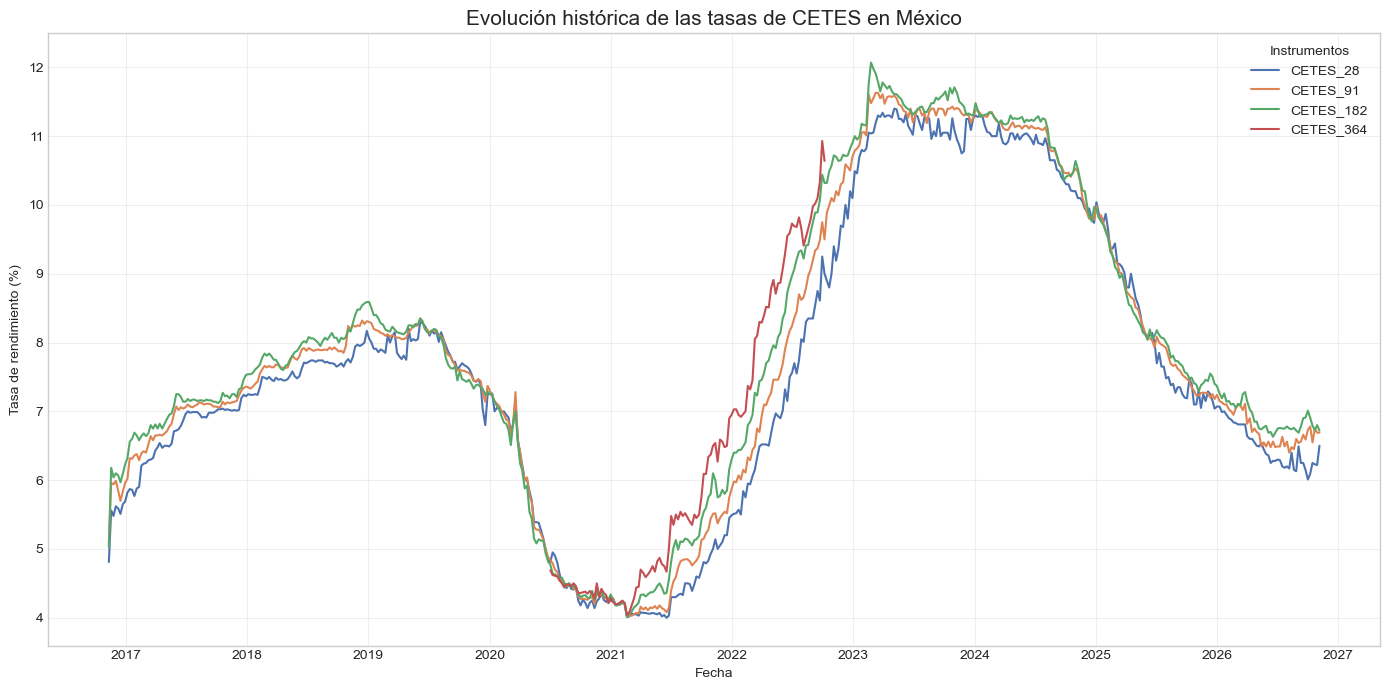

In [14]:
plt.figure(figsize=(14, 7))

for columna in series_cetes.keys():

    plt.plot(
        datos_cetes["fecha"],
        datos_cetes[columna],
        label=columna
    )

plt.title(
    "Evolución histórica de las tasas de CETES en México",
    fontsize=15
)

plt.xlabel("Fecha")
plt.ylabel("Tasa de rendimiento (%)")

plt.legend(title="Instrumentos")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [15]:
columnas_cetes = [
    "CETES_28",
    "CETES_91",
    "CETES_182",
    "CETES_364"
]

resumen_fechas = []

for columna in columnas_cetes:

    fechas_validas = datos_cetes.loc[
        datos_cetes[columna].notna(),
        "fecha"
    ]

    resumen_fechas.append({
        "Instrumento": columna,
        "Observaciones": fechas_validas.count(),
        "Primera fecha": fechas_validas.min(),
        "Última fecha": fechas_validas.max(),
        "Datos faltantes": datos_cetes[columna].isna().sum()
    })

tabla_revision = pd.DataFrame(resumen_fechas)

display(tabla_revision)

,Instrumento,Observaciones,Primera fecha,Última fecha,Datos faltantes
0,CETES_28,522,2016-11-10,2026-11-05,0
1,CETES_91,522,2016-11-10,2026-11-05,0
2,CETES_182,522,2016-11-10,2026-11-05,0
3,CETES_364,273,2016-11-10,2026-10-29,249


In [16]:
print(
    "Fechas duplicadas:",
    datos_cetes["fecha"].duplicated().sum()
)

Fechas duplicadas: 0


In [17]:
display(
    datos_cetes[columnas_cetes].describe().round(3)
)

,CETES_28,CETES_91,CETES_182,CETES_364
count,522.000,522.000,522.000,273.000
mean,7.581,7.786,7.929,7.776
std,2.121,2.148,2.148,2.363
min,4.000,4.020,4.010,4.040
25%,6.250,6.542,6.750,5.750
50%,7.400,7.565,7.645,7.510
75%,8.875,9.180,9.392,9.730
max,11.400,11.630,12.070,12.090


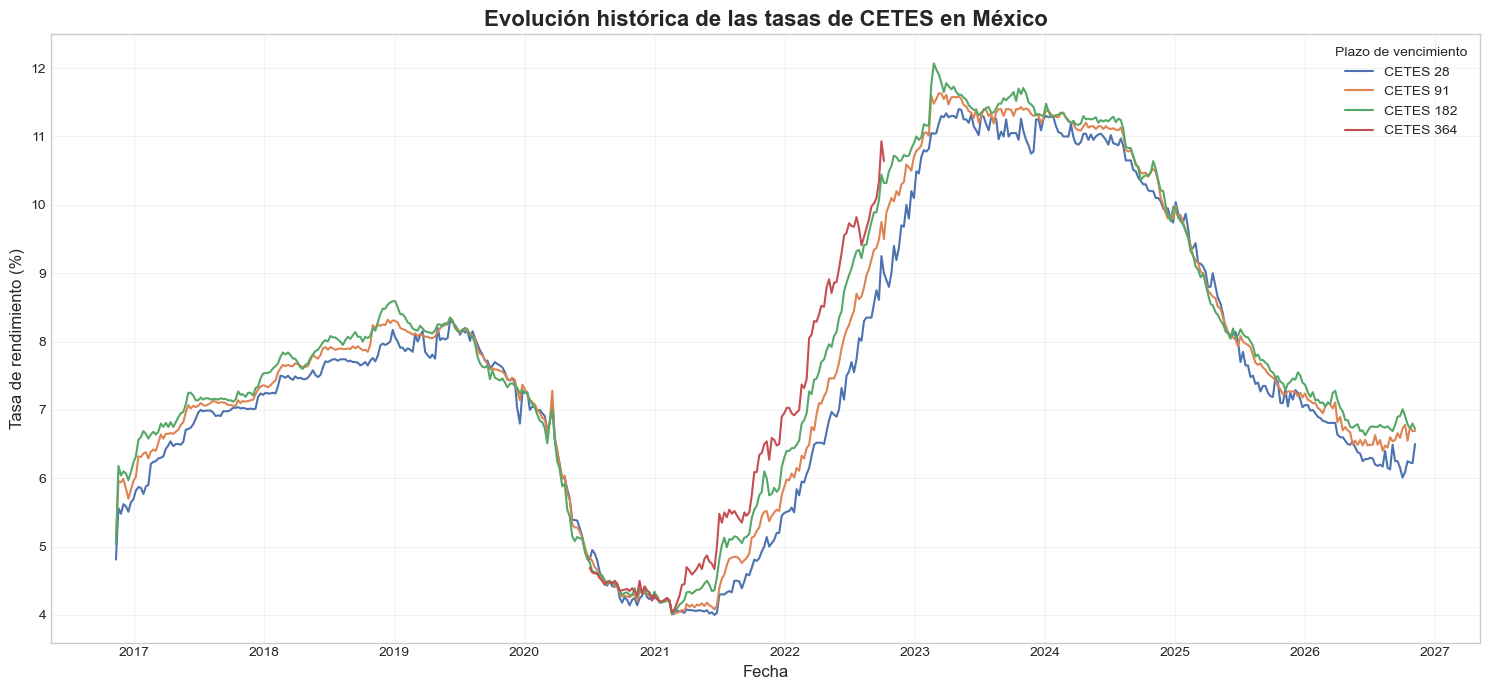

In [20]:
plt.figure(figsize=(15, 7))

for columna in columnas_cetes:

    plt.plot(
        datos_cetes["fecha"],
        datos_cetes[columna],
        label=columna.replace("_", " "),
        linewidth=1.5
    )

plt.title(
    "Evolución histórica de las tasas de CETES en México",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Fecha", fontsize=12)
plt.ylabel("Tasa de rendimiento (%)", fontsize=12)

plt.legend(title="Plazo de vencimiento")

plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    carpeta / "grafica_historica_cetes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
from pathlib import Path

# Crear la carpeta del proyecto
carpeta = Path("Proyecto_Convexidad_CETES")

# Crear la carpeta si todavía no existe
carpeta.mkdir(exist_ok=True)

print("Carpeta preparada correctamente")

Carpeta preparada correctamente


In [21]:
# Obtener fechas donde existen datos de CETES a 364 días
fechas_364 = (
    datos_cetes.loc[
        datos_cetes["CETES_364"].notna(),
        "fecha"
    ]
    .sort_values()
)

# Calcular días entre observaciones
intervalos = fechas_364.diff().dt.days

print("Frecuencia de días entre observaciones:")

display(
    intervalos.value_counts().sort_index().to_frame(
        name="Cantidad de intervalos"
    )
)

Frecuencia de días entre observaciones:


,Cantidad de intervalos
fecha,
6.0,3
7.0,112
8.0,3
13.0,6
14.0,95
15.0,6
21.0,1
27.0,1
28.0,43


In [22]:
# Identificar fechas sin observaciones de CETES a 364 días
faltantes_364 = datos_cetes.loc[
    datos_cetes["CETES_364"].isna(),
    "fecha"
]

print("Primeras 15 fechas sin observación:")

display(faltantes_364.head(15))

Primeras 15 fechas sin observación:


1    2016-11-17
2    2016-11-24
3    2016-12-01
5    2016-12-15
6    2016-12-22
7    2016-12-29
9    2017-01-12
10   2017-01-19
11   2017-01-26
13   2017-02-09
14   2017-02-16
15   2017-02-23
17   2017-03-09
18   2017-03-16
19   2017-03-23
Name: fecha, dtype: datetime64[ns]

In [23]:
print("Días de la semana de las observaciones:")

display(
    fechas_364.dt.day_name().value_counts()
)

Días de la semana de las observaciones:


fecha
Thursday     262
Wednesday     11
Name: count, dtype: int64

In [24]:
# Mostrar las primeras 20 observaciones disponibles
display(
    datos_cetes.loc[
        datos_cetes["CETES_364"].notna(),
        ["fecha", "CETES_364"]
    ].head(20)
)

,fecha,CETES_364
0,2016-11-10,5.31
4,2016-12-08,6.20
8,2017-01-05,6.68
12,2017-02-02,6.92
16,2017-03-02,6.92
20,2017-03-30,6.90
24,2017-04-27,6.99
28,2017-05-25,7.23
32,2017-06-22,7.20
36,2017-07-20,7.23


In [25]:
# Identificar las fechas de los otros plazos
# en las que no existe observación de CETES a 364 días

revision_364 = datos_cetes.loc[
    datos_cetes["CETES_364"].isna(),
    ["fecha", "CETES_28", "CETES_91", "CETES_182"]
]

display(revision_364.head(15))

,fecha,CETES_28,CETES_91,CETES_182
1,2016-11-17,5.56,5.96,6.18
2,2016-11-24,5.48,5.94,6.04
3,2016-12-01,5.62,5.99,6.10
5,2016-12-15,5.51,5.70,5.97
6,2016-12-22,5.65,5.83,6.09
7,2016-12-29,5.69,5.96,6.23
9,2017-01-12,5.87,6.32,6.56
10,2017-01-19,5.86,6.31,6.60
11,2017-01-26,5.77,6.36,6.69
13,2017-02-09,5.90,6.29,6.58


In [26]:
# Seleccionar las observaciones donde existen
# datos para los cuatro plazos

curva_cetes = datos_cetes.dropna(
    subset=columnas_cetes
).copy()

# Ordenar por fecha
curva_cetes = curva_cetes.sort_values("fecha")

# Reiniciar índices
curva_cetes = curva_cetes.reset_index(drop=True)

# Mostrar resultados
print("Observaciones coincidentes:", len(curva_cetes))

display(curva_cetes.head(10))

Observaciones coincidentes: 273


,fecha,CETES_28,CETES_91,CETES_182,CETES_364
0,2016-11-10,4.81,5.07,5.03,5.31
1,2016-12-08,5.59,5.85,6.07,6.20
2,2017-01-05,5.82,6.02,6.32,6.68
3,2017-02-02,5.88,6.38,6.65,6.92
4,2017-03-02,6.25,6.40,6.64,6.92
5,2017-03-30,6.43,6.65,6.81,6.90
6,2017-04-27,6.50,6.68,6.82,6.99
7,2017-05-25,6.71,6.96,7.08,7.23
8,2017-06-22,6.87,7.04,7.14,7.20
9,2017-07-20,6.99,7.06,7.17,7.23


In [27]:
# Seleccionar la última fecha disponible
fecha_seleccionada = curva_cetes["fecha"].max()

# Obtener los rendimientos de esa fecha
datos_fecha = curva_cetes[
    curva_cetes["fecha"] == fecha_seleccionada
]

display(datos_fecha)

,fecha,CETES_28,CETES_91,CETES_182,CETES_364
272,2026-10-29,6.22,6.69,6.8,7.12


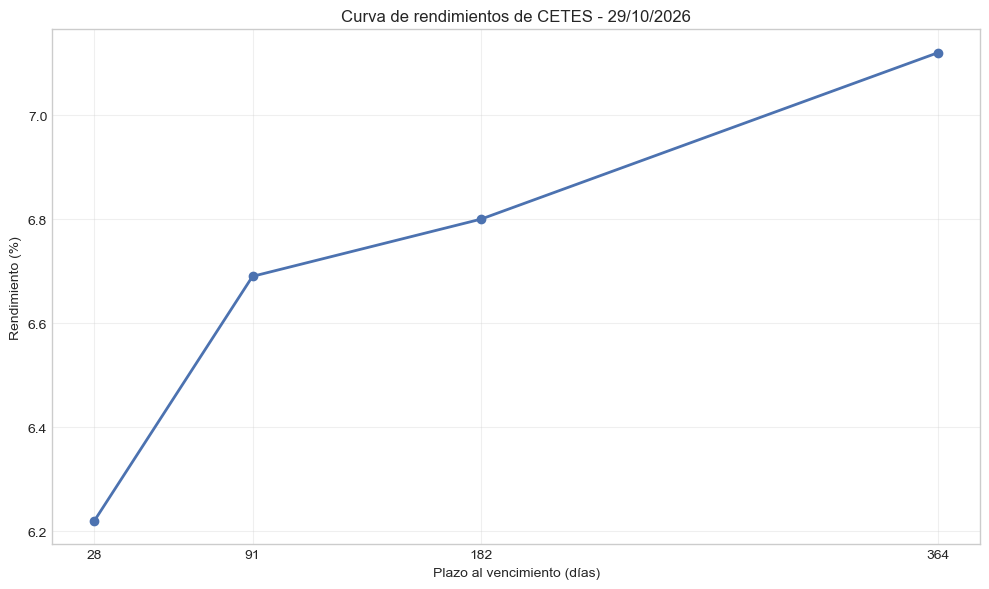

In [28]:
# Plazos de los CETES
plazos = [28, 91, 182, 364]

# Obtener rendimientos
tasas = datos_fecha[columnas_cetes].values.flatten()

# Crear gráfica
plt.figure(figsize=(10, 6))

plt.plot(
    plazos,
    tasas,
    marker="o",
    linewidth=2
)

plt.title(
    f"Curva de rendimientos de CETES - {fecha_seleccionada:%d/%m/%Y}"
)

plt.xlabel("Plazo al vencimiento (días)")
plt.ylabel("Rendimiento (%)")

plt.xticks(plazos)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Crear tabla de rendimientos por plazo

curva_actual = pd.DataFrame({
    "Plazo (días)": [28, 91, 182, 364],
    "Rendimiento (%)": tasas
})

# Calcular diferencias entre plazos
curva_actual["Diferencia (pp)"] = (
    curva_actual["Rendimiento (%)"].diff()
)

display(curva_actual.round(4))

,Plazo (días),Rendimiento (%),Diferencia (pp)
0,28,6.22,NaN
1,91,6.69,0.47
2,182,6.80,0.11
3,364,7.12,0.32


In [31]:
# Calcular el diferencial entre el plazo más largo
# y el plazo más corto

tasa_28 = curva_actual.iloc[0]["Rendimiento (%)"]
tasa_364 = curva_actual.iloc[-1]["Rendimiento (%)"]

diferencial = tasa_364 - tasa_28

print("Diferencial:", round(diferencial, 4), "puntos porcentuales")

print(
    "Diferencial en puntos base:",
    round(diferencial * 100, 2),
    "pb"
)

Diferencial: 0.9 puntos porcentuales
Diferencial en puntos base: 90.0 pb


In [33]:
def precio_cete(valor_nominal, tasa, dias):

    tasa_decimal = tasa / 100

    precio = valor_nominal / (
        1 + tasa_decimal * (dias / 360)
    )

    return precio

In [34]:
# Datos hipotéticos
valor_nominal = 10
tasa = 7.12
dias = 364

precio = precio_cete(
    valor_nominal,
    tasa,
    dias
)

print("Precio teórico del CETE:", round(precio, 4))

Precio teórico del CETE: 9.3284


In [35]:
# Parámetros del CETE
valor_nominal = 10
dias = 364
tasa_base = 7.12

# Escenarios de tasas
tasas_escenarios = [
    5.12, 6.12, 7.12, 8.12, 9.12
]

# Calcular precios
precios = []

for tasa in tasas_escenarios:

    precio = precio_cete(
        valor_nominal,
        tasa,
        dias
    )

    precios.append(precio)

# Crear tabla
escenarios = pd.DataFrame({
    "Tasa (%)": tasas_escenarios,
    "Precio (MXN)": precios
})

display(escenarios.round(4))

,Tasa (%),Precio (MXN)
0,5.12,9.5078
1,6.12,9.4173
2,7.12,9.3284
3,8.12,9.2413
4,9.12,9.1557


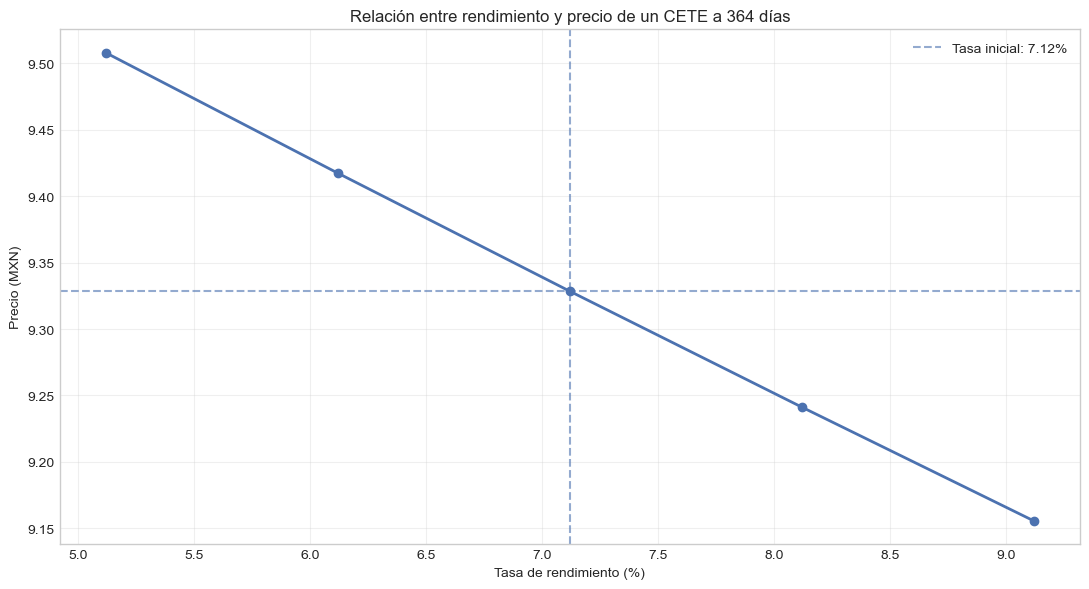

In [36]:
plt.figure(figsize=(11, 6))

plt.plot(
    escenarios["Tasa (%)"],
    escenarios["Precio (MXN)"],
    marker="o",
    linewidth=2
)

plt.axvline(
    tasa_base,
    linestyle="--",
    alpha=0.6,
    label="Tasa inicial: 7.12%"
)

plt.axhline(
    precio_cete(valor_nominal, tasa_base, dias),
    linestyle="--",
    alpha=0.6
)

plt.title(
    "Relación entre rendimiento y precio de un CETE a 364 días"
)

plt.xlabel("Tasa de rendimiento (%)")
plt.ylabel("Precio (MXN)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# Parámetros del CETE
VN = 10
dias = 364
tasa_base = 7.12

# Convertir tasa porcentual a decimal
y = tasa_base / 100

# Plazo expresado en años comerciales
t = dias / 360

# Precio inicial
P0 = VN / (1 + y * t)

# Duración modificada
duracion_mod = t / (1 + y * t)

# Convexidad
convexidad = 2 * t**2 / (1 + y * t)**2

print("Precio inicial:", round(P0, 6))
print("Duración modificada:", round(duracion_mod, 6))
print("Convexidad:", round(convexidad, 6))

Precio inicial: 9.328436
Duración modificada: 0.943208
Convexidad: 1.779284


In [38]:
# Cambios hipotéticos en las tasas
cambios_tasa = [-0.02, -0.01, 0.01, 0.02]

resultados = []

for cambio in cambios_tasa:

    # Nueva tasa
    nueva_y = y + cambio

    # Precio exacto
    nuevo_precio = VN / (1 + nueva_y * t)

    # Variación porcentual real
    variacion_real = (nuevo_precio - P0) / P0

    # Estimación mediante duración
    estimacion_duracion = -duracion_mod * cambio

    # Estimación mediante duración y convexidad
    estimacion_completa = (
        -duracion_mod * cambio
        + 0.5 * convexidad * cambio**2
    )

    resultados.append({
        "Cambio de tasa (pp)": cambio * 100,
        "Variación real (%)": variacion_real * 100,
        "Estimación duración (%)": estimacion_duracion * 100,
        "Estimación duración + convexidad (%)":
            estimacion_completa * 100
    })

comparacion = pd.DataFrame(resultados)

display(comparacion.round(5))

,Cambio de tasa (pp),Variación real (%),Estimación duración (%),Estimación duración + convexidad (%)
0,-2.0,1.92269,1.88642,1.92200
1,-1.0,0.95219,0.94321,0.95210
2,1.0,-0.93440,-0.94321,-0.93431
3,2.0,-1.85149,-1.88642,-1.85083


In [39]:
# Calcular errores absolutos de las aproximaciones

comparacion["Error duración"] = abs(
    comparacion["Variación real (%)"]
    - comparacion["Estimación duración (%)"]
)

comparacion["Error duración + convexidad"] = abs(
    comparacion["Variación real (%)"]
    - comparacion["Estimación duración + convexidad (%)"]
)

display(comparacion.round(6))

,Cambio de tasa (pp),Variación real (%),Estimación duración (%),Estimación duración + convexidad (%),Error duración,Error duración + convexidad
0,-2.0,1.922687,1.886417,1.922003,0.036270,0.000684
1,-1.0,0.952190,0.943208,0.952105,0.008981,0.000085
2,1.0,-0.934395,-0.943208,-0.934312,0.008813,0.000083
3,2.0,-1.851490,-1.886417,-1.850831,0.034927,0.000659


In [41]:
error_duracion = comparacion["Error duración"].mean()

error_convexidad = comparacion[
    "Error duración + convexidad"
].mean()

mejora = (
    (error_duracion - error_convexidad)
    / error_duracion
) * 100

print("Error promedio usando duración:", round(error_duracion, 6), "%")

print(
    "Error promedio usando duración y convexidad:",
    round(error_convexidad, 6),
    "%"
)

print("Mejora porcentual:", round(mejora, 2), "%")

Error promedio usando duración: 0.022248 %
Error promedio usando duración y convexidad: 0.000378 %
Mejora porcentual: 98.3 %


In [42]:
def simulador_cete(valor_nominal, dias, tasa_inicial, cambio_pb):

    # Convertir tasas a decimales
    y = tasa_inicial / 100
    cambio_y = cambio_pb / 10000

    # Plazo comercial
    t = dias / 360

    # Precio inicial
    precio_inicial = valor_nominal / (1 + y * t)

    # Duración modificada
    duracion = t / (1 + y * t)

    # Convexidad
    convexidad = 2 * t**2 / (1 + y * t)**2

    # Nueva tasa
    nueva_tasa = y + cambio_y

    if 1 + nueva_tasa * t <= 0:
        raise ValueError("La tasa genera un denominador no válido.")

    # Nuevo precio exacto
    nuevo_precio = valor_nominal / (1 + nueva_tasa * t)

    # Variación real
    variacion_real = (nuevo_precio / precio_inicial) - 1

    # Aproximación por duración
    estimacion_duracion = -duracion * cambio_y

    # Aproximación por duración y convexidad
    estimacion_completa = (
        -duracion * cambio_y
        + 0.5 * convexidad * cambio_y**2
    )

    return {
        "Precio inicial": precio_inicial,
        "Nuevo precio": nuevo_precio,
        "Nueva tasa (%)": nueva_tasa * 100,
        "Duración modificada": duracion,
        "Convexidad": convexidad,
        "Variación real (%)": variacion_real * 100,
        "Estimación duración (%)": estimacion_duracion * 100,
        "Estimación duración + convexidad (%)": estimacion_completa * 100
    }

In [43]:
resultado = simulador_cete(
    valor_nominal=10,
    dias=364,
    tasa_inicial=7.12,
    cambio_pb=100
)

for indicador, valor in resultado.items():
    print(f"{indicador}: {valor:.6f}")

Precio inicial: 9.328436
Nuevo precio: 9.241271
Nueva tasa (%): 8.120000
Duración modificada: 0.943208
Convexidad: 1.779284
Variación real (%): -0.934395
Estimación duración (%): -0.943208
Estimación duración + convexidad (%): -0.934312


In [44]:
cambios_pb = [-200, -100, -50, 0, 50, 100, 200]

resultados_simulador = []

for cambio in cambios_pb:

    resultado = simulador_cete(
        valor_nominal=10,
        dias=364,
        tasa_inicial=7.12,
        cambio_pb=cambio
    )

    resultados_simulador.append({
        "Cambio (pb)": cambio,
        "Nuevo precio": resultado["Nuevo precio"],
        "Variación real (%)": resultado["Variación real (%)"],
        "Duración (%)": resultado["Estimación duración (%)"],
        "Duración + convexidad (%)":
            resultado["Estimación duración + convexidad (%)"]
    })

tabla_simulador = pd.DataFrame(resultados_simulador)

display(tabla_simulador.round(5))

,Cambio (pb),Nuevo precio,Variación real (%),Duración (%),Duración + convexidad (%)
0,-200,9.50779,1.92269,1.88642,1.92200
1,-100,9.41726,0.95219,0.94321,0.95210
2,-50,9.37264,0.47384,0.47160,0.47383
3,0,9.32844,0.00000,-0.00000,0.00000
4,50,9.28465,-0.46939,-0.47160,-0.46938
5,100,9.24127,-0.93440,-0.94321,-0.93431
6,200,9.15572,-1.85149,-1.88642,-1.85083


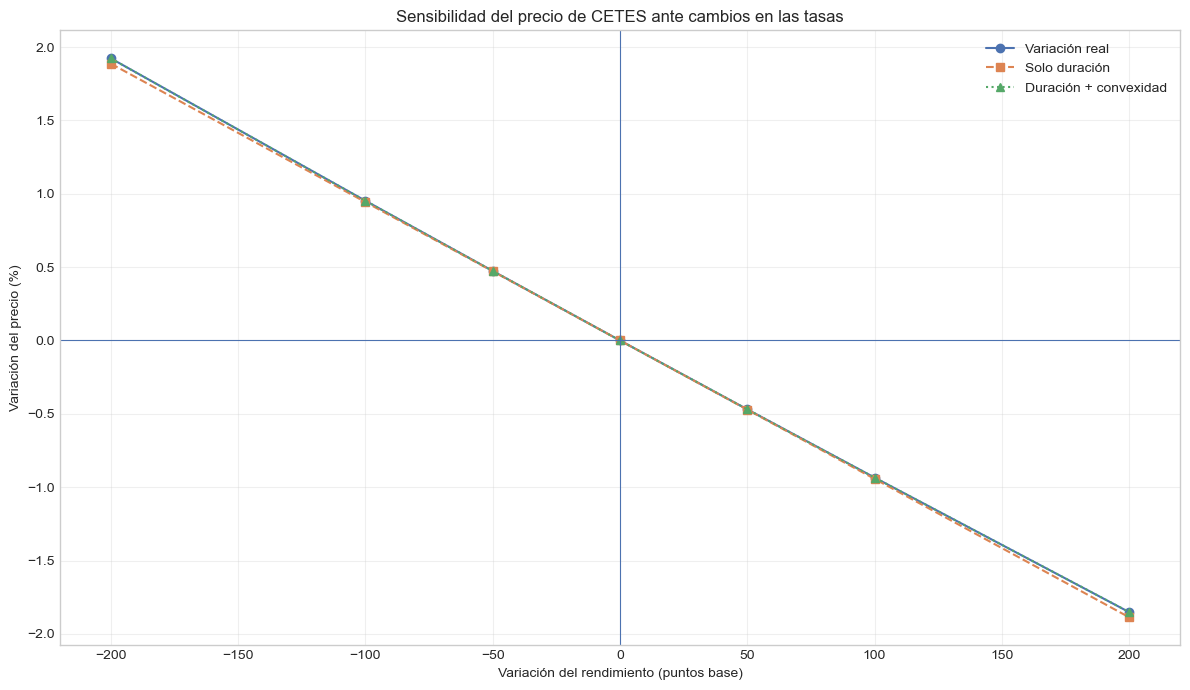

In [45]:
plt.figure(figsize=(12, 7))

plt.plot(
    tabla_simulador["Cambio (pb)"],
    tabla_simulador["Variación real (%)"],
    marker="o",
    label="Variación real"
)

plt.plot(
    tabla_simulador["Cambio (pb)"],
    tabla_simulador["Duración (%)"],
    marker="s",
    linestyle="--",
    label="Solo duración"
)

plt.plot(
    tabla_simulador["Cambio (pb)"],
    tabla_simulador["Duración + convexidad (%)"],
    marker="^",
    linestyle=":",
    label="Duración + convexidad"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.title(
    "Sensibilidad del precio de CETES ante cambios en las tasas"
)

plt.xlabel("Variación del rendimiento (puntos base)")
plt.ylabel("Variación del precio (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
plazos_cetes = [28, 91, 182, 364]

comparacion_plazos = []

for plazo in plazos_cetes:

    resultado = simulador_cete(
        valor_nominal=10,
        dias=plazo,
        tasa_inicial=7.12,
        cambio_pb=100
    )

    comparacion_plazos.append({
        "Plazo (días)": plazo,
        "Precio inicial": resultado["Precio inicial"],
        "Duración modificada": resultado["Duración modificada"],
        "Convexidad": resultado["Convexidad"],
        "Variación real (%)": resultado["Variación real (%)"]
    })

tabla_plazos = pd.DataFrame(comparacion_plazos)

display(tabla_plazos.round(6))

,Plazo (días),Precio inicial,Duración modificada,Convexidad,Variación real (%)
0,28,9.944927,0.077349,0.011966,-0.077290
1,91,9.823204,0.248309,0.123314,-0.247694
2,182,9.652551,0.487990,0.476269,-0.485620
3,364,9.328436,0.943208,1.779284,-0.934395


Los resultados muestran una relación positiva entre el plazo de vencimiento, la duración modificada y la convexidad de los CETES. Conforme aumenta el plazo, también aumenta la sensibilidad del precio ante variaciones en las tasas de interés. En particular, el CETE a 364 días presenta una mayor variación de precio que el CETE a 28 días ante un mismo incremento de 100 puntos base. Esto permite observar que los instrumentos de mayor vencimiento están más expuestos al riesgo de tasa de interés.

In [47]:
plazos_cetes = [28, 91, 182, 364]

comparacion_plazos = []

for plazo in plazos_cetes:

    resultado = simulador_cete(
        valor_nominal=10,
        dias=plazo,
        tasa_inicial=7.12,
        cambio_pb=100
    )

    comparacion_plazos.append({
        "Plazo (días)": plazo,
        "Precio inicial": resultado["Precio inicial"],
        "Duración modificada": resultado["Duración modificada"],
        "Convexidad": resultado["Convexidad"],
        "Variación real (%)": resultado["Variación real (%)"],
        "Estimación duración (%)": resultado["Estimación duración (%)"],
        "Estimación duración + convexidad (%)":
            resultado["Estimación duración + convexidad (%)"]
    })

tabla_comparacion = pd.DataFrame(comparacion_plazos)

display(tabla_comparacion.round(6))

,Plazo (días),Precio inicial,Duración modificada,Convexidad,Variación real (%),Estimación duración (%),Estimación duración + convexidad (%)
0,28,9.944927,0.077349,0.011966,-0.077290,-0.077349,-0.077290
1,91,9.823204,0.248309,0.123314,-0.247694,-0.248309,-0.247692
2,182,9.652551,0.487990,0.476269,-0.485620,-0.487990,-0.485609
3,364,9.328436,0.943208,1.779284,-0.934395,-0.943208,-0.934312


In [48]:
tabla_comparacion["Error duración"] = abs(
    tabla_comparacion["Variación real (%)"] -
    tabla_comparacion["Estimación duración (%)"]
)

tabla_comparacion["Error duración + convexidad"] = abs(
    tabla_comparacion["Variación real (%)"] -
    tabla_comparacion["Estimación duración + convexidad (%)"]
)

display(tabla_comparacion.round(6))

,Plazo (días),Precio inicial,Duración modificada,Convexidad,Variación real (%),Estimación duración (%),Estimación duración + convexidad (%),Error duración,Error duración + convexidad
0,28,9.944927,0.077349,0.011966,-0.077290,-0.077349,-0.077290,0.000060,0.000000
1,91,9.823204,0.248309,0.123314,-0.247694,-0.248309,-0.247692,0.000615,0.000002
2,182,9.652551,0.487990,0.476269,-0.485620,-0.487990,-0.485609,0.002370,0.000012
3,364,9.328436,0.943208,1.779284,-0.934395,-0.943208,-0.934312,0.008813,0.000083


In [49]:
tabla_comparacion["Mejora (%)"] = (
    (tabla_comparacion["Error duración"] -
     tabla_comparacion["Error duración + convexidad"])
    / tabla_comparacion["Error duración"]
) * 100

display(
    tabla_comparacion[
        ["Plazo (días)",
         "Error duración",
         "Error duración + convexidad",
         "Mejora (%)"]
    ].round(4)
)

,Plazo (días),Error duración,Error duración + convexidad,Mejora (%)
0,28,0.0001,0.0000,99.9227
1,91,0.0006,0.0000,99.7517
2,182,0.0024,0.0000,99.5120
3,364,0.0088,0.0001,99.0568


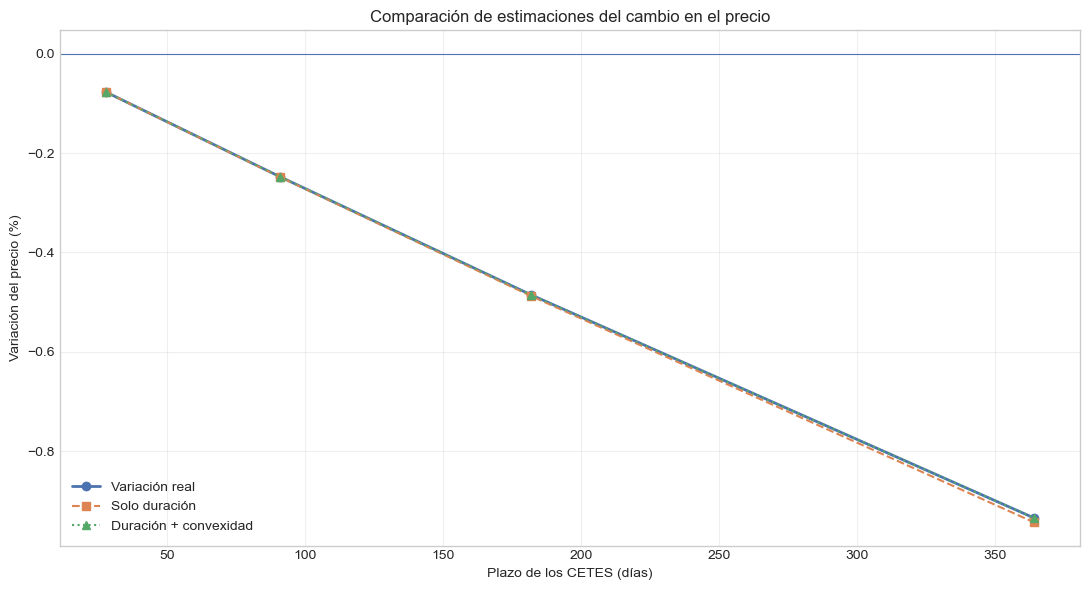

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    tabla_comparacion["Plazo (días)"],
    tabla_comparacion["Variación real (%)"],
    marker="o",
    linewidth=2,
    label="Variación real"
)

plt.plot(
    tabla_comparacion["Plazo (días)"],
    tabla_comparacion["Estimación duración (%)"],
    marker="s",
    linestyle="--",
    label="Solo duración"
)

plt.plot(
    tabla_comparacion["Plazo (días)"],
    tabla_comparacion["Estimación duración + convexidad (%)"],
    marker="^",
    linestyle=":",
    label="Duración + convexidad"
)

plt.title("Comparación de estimaciones del cambio en el precio")
plt.xlabel("Plazo de los CETES (días)")
plt.ylabel("Variación del precio (%)")

plt.axhline(0, linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

In [51]:
cambios_pb = [-200, -100, -50, 0, 50, 100, 200]
plazos_cetes = [28, 91, 182, 364]

escenarios = []

for plazo in plazos_cetes:

    for cambio in cambios_pb:

        resultado = simulador_cete(
            valor_nominal=10,
            dias=plazo,
            tasa_inicial=7.12,
            cambio_pb=cambio
        )

        escenarios.append({
            "Plazo (días)": plazo,
            "Cambio (pb)": cambio,
            "Nueva tasa (%)": resultado["Nueva tasa (%)"],
            "Precio inicial": resultado["Precio inicial"],
            "Nuevo precio": resultado["Nuevo precio"],
            "Variación real (%)": resultado["Variación real (%)"],
            "Estimación duración + convexidad (%)":
                resultado["Estimación duración + convexidad (%)"]
        })

tabla_escenarios = pd.DataFrame(escenarios)

display(tabla_escenarios.round(5))

,Plazo (días),Cambio (pb),Nueva tasa (%),Precio inicial,Nuevo precio,Variación real (%),Estimación duración + convexidad (%)
0,28,-200,5.12,9.94493,9.96034,0.15494,0.15494
1,28,-100,6.12,9.94493,9.95263,0.07741,0.07741
2,28,-50,6.62,9.94493,9.94877,0.03869,0.03869
3,28,0,7.12,9.94493,9.94493,0.00000,0.00000
4,28,50,7.62,9.94493,9.94108,-0.03866,-0.03866
5,28,100,8.12,9.94493,9.93724,-0.07729,-0.07729
6,28,200,9.12,9.94493,9.92957,-0.15446,-0.15446
7,91,-200,5.12,9.82320,9.87223,0.49910,0.49908
8,91,-100,6.12,9.82320,9.84766,0.24893,0.24893
9,91,-50,6.62,9.82320,9.83542,0.12431,0.12431


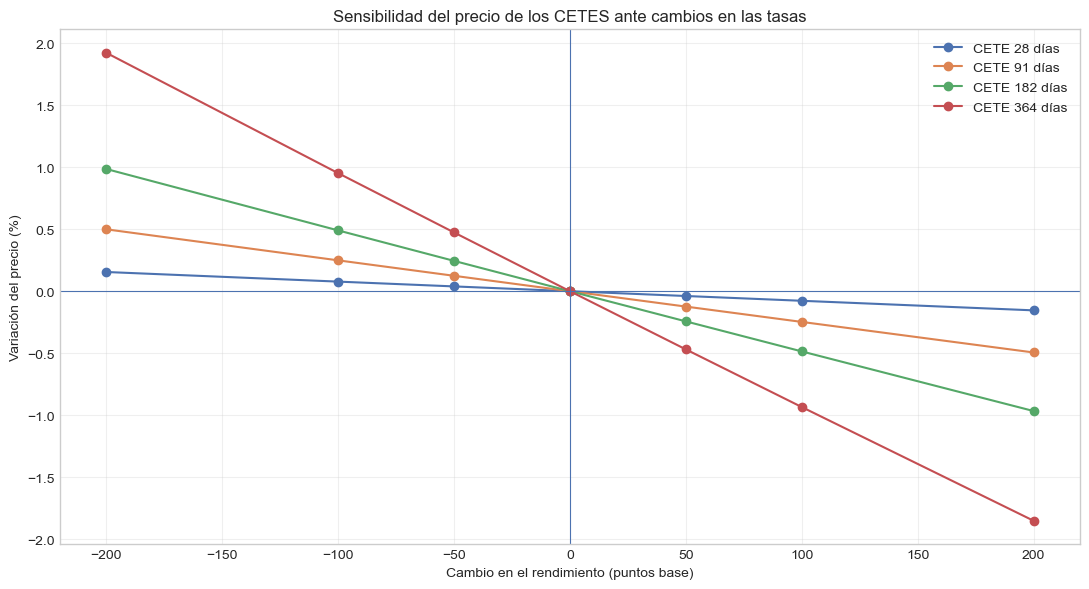

In [52]:
plt.figure(figsize=(11, 6))

for plazo in plazos_cetes:

    datos_plazo = tabla_escenarios[
        tabla_escenarios["Plazo (días)"] == plazo
    ]

    plt.plot(
        datos_plazo["Cambio (pb)"],
        datos_plazo["Variación real (%)"],
        marker="o",
        label=f"CETE {plazo} días"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.title("Sensibilidad del precio de los CETES ante cambios en las tasas")
plt.xlabel("Cambio en el rendimiento (puntos base)")
plt.ylabel("Variación del precio (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
display(tabla_escenarios.round(5).style.hide(axis="index"))

Plazo (días),Cambio (pb),Nueva tasa (%),Precio inicial,Nuevo precio,Variación real (%),Estimación duración + convexidad (%)
28,-200,5.120000,9.944930,9.960340,0.154940,0.154940
28,-100,6.120000,9.944930,9.952630,0.077410,0.077410
28,-50,6.620000,9.944930,9.948770,0.038690,0.038690
28,0,7.120000,9.944930,9.944930,0.000000,0.000000
28,50,7.620000,9.944930,9.941080,-0.038660,-0.038660
28,100,8.120000,9.944930,9.937240,-0.077290,-0.077290
28,200,9.120000,9.944930,9.929570,-0.154460,-0.154460
91,-200,5.120000,9.823200,9.872230,0.499100,0.499080
91,-100,6.120000,9.823200,9.847660,0.248930,0.248930
91,-50,6.620000,9.823200,9.835420,0.124310,0.124310


In [54]:
resumen_escenarios = tabla_escenarios.groupby(
    "Plazo (días)"
).agg(
    Ganancia_maxima=("Variación real (%)", "max"),
    Perdida_maxima=("Variación real (%)", "min"),
    Variacion_promedio=("Variación real (%)", "mean")
).reset_index()

display(resumen_escenarios.round(5))

,Plazo (días),Ganancia_maxima,Perdida_maxima,Variacion_promedio
0,28,0.15494,-0.15446,0.00009
1,91,0.49910,-0.49416,0.00092
2,182,0.98560,-0.96655,0.00357
3,364,1.92269,-1.85149,0.01335


La simulación de escenarios permitió identificar que los CETES de mayor plazo presentan una mayor sensibilidad ante cambios en las tasas de interés. El instrumento a 364 días registró la mayor variación de precio, tanto positiva como negativa, ante los cambios simulados de 200 puntos base. Esto demuestra la importancia de considerar la duración modificada y la convexidad al evaluar la exposición al riesgo de tasa de interés. Por otra parte, la convexidad positiva explica que los incrementos de precio ante disminuciones de tasas sean ligeramente superiores a las pérdidas ante aumentos equivalentes.

In [55]:
inversion_inicial = 100000

tabla_escenarios["Ganancia o pérdida ($)"] = (
    inversion_inicial *
    tabla_escenarios["Variación real (%)"] / 100
)

tabla_escenarios["Valor final ($)"] = (
    inversion_inicial +
    tabla_escenarios["Ganancia o pérdida ($)"]
)

display(
    tabla_escenarios[
        ["Plazo (días)",
         "Cambio (pb)",
         "Variación real (%)",
         "Ganancia o pérdida ($)",
         "Valor final ($)"]
    ].round(2).style.hide(axis="index")
)

Plazo (días),Cambio (pb),Variación real (%),Ganancia o pérdida ($),Valor final ($)
28,-200,0.150000,154.940000,100154.940000
28,-100,0.080000,77.410000,100077.410000
28,-50,0.040000,38.690000,100038.690000
28,0,0.000000,0.000000,100000.000000
28,50,-0.040000,-38.660000,99961.340000
28,100,-0.080000,-77.290000,99922.710000
28,200,-0.150000,-154.460000,99845.540000
91,-200,0.500000,499.100000,100499.100000
91,-100,0.250000,248.930000,100248.930000
91,-50,0.120000,124.310000,100124.310000


In [56]:
# Datos de comprobación
valor_nominal = 10
tasa = 7.12 / 100
dias = 364

# Precio calculado con nuestra función
precio_modelo = valor_nominal / (1 + tasa * (dias / 360))

print(f"Precio teórico del CETE: ${precio_modelo:.6f}")

Precio teórico del CETE: $9.328436


In [61]:
import os

if "BANXICO_TOKEN" in os.environ:
    print("Token de BANXICO disponible.")
else:
    print("Es necesario volver a introducir el token.")

Token de BANXICO disponible.


In [62]:
import os
import requests
import pandas as pd

# Series oficiales de CETES a 28 días
series_mercado = {
    "SF45422": "plazo",
    "SF45438": "precio_mercado",
    "SF45470": "tasa_rendimiento"
}

# Periodo de análisis
fecha_inicio = "2016-11-05"
fecha_fin = "2026-11-09"

# Token que ya tenemos configurado
token = os.environ["BANXICO_TOKEN"]

lista_mercado = []

for serie, nombre in series_mercado.items():

    url = (
        f"https://www.banxico.org.mx/SieAPIRest/service/v1/"
        f"series/{serie}/datos/{fecha_inicio}/{fecha_fin}"
    )

    respuesta = requests.get(
        url,
        headers={"Bmx-Token": token},
        timeout=60
    )

    respuesta.raise_for_status()

    datos = respuesta.json()["bmx"]["series"][0]["datos"]

    df = pd.DataFrame(datos)

    df = df.rename(columns={"dato": nombre})

    df = df[["fecha", nombre]]

    df[nombre] = pd.to_numeric(
        df[nombre].str.replace(",", "", regex=False),
        errors="coerce"
    )

    df["fecha"] = pd.to_datetime(
        df["fecha"],
        format="%d/%m/%Y"
    )

    lista_mercado.append(df)

# Unir las tres series por fecha
datos_mercado_28 = lista_mercado[0]

for df in lista_mercado[1:]:
    datos_mercado_28 = datos_mercado_28.merge(
        df,
        on="fecha",
        how="outer"
    )

datos_mercado_28 = datos_mercado_28.sort_values("fecha")

print("Observaciones descargadas:", len(datos_mercado_28))

display(datos_mercado_28.tail(10))

Observaciones descargadas: 2516


,fecha,plazo,precio_mercado,tasa_rendimiento
2506,2026-10-26,24.0,9.957732,6.367113
2507,2026-10-27,23.0,9.959975,6.289958
2508,2026-10-28,22.0,9.960798,6.440119
2509,2026-10-29,28.0,9.951008,6.329983
2510,2026-10-30,27.0,9.952102,6.417137
2511,2026-11-03,23.0,9.958644,6.499994
2512,2026-11-04,22.0,9.960435,6.499990
2513,2026-11-05,28.0,9.950487,6.397634
2514,2026-11-06,27.0,9.952972,6.300028
2515,2026-11-09,24.0,9.958089,6.313109


In [63]:
# Crear una copia de los datos de mercado
comparacion_28 = datos_mercado_28.copy()

# Eliminar observaciones incompletas
comparacion_28 = comparacion_28.dropna(
    subset=["plazo", "precio_mercado", "tasa_rendimiento"]
)

# Valor nominal del CETE
VN = 10

# Convertir tasa porcentual a decimal
comparacion_28["tasa_decimal"] = (
    comparacion_28["tasa_rendimiento"] / 100
)

# Calcular el precio teórico
comparacion_28["precio_teorico"] = VN / (
    1 + comparacion_28["tasa_decimal"]
    * comparacion_28["plazo"] / 360
)

# Calcular el error en pesos
comparacion_28["error_precio"] = (
    comparacion_28["precio_teorico"]
    - comparacion_28["precio_mercado"]
)

# Calcular el error absoluto
comparacion_28["error_absoluto"] = (
    comparacion_28["error_precio"].abs()
)

# Calcular el error porcentual absoluto
comparacion_28["error_porcentual"] = (
    comparacion_28["error_absoluto"]
    / comparacion_28["precio_mercado"]
    * 100
)

# Mostrar resultados
display(
    comparacion_28[
        [
            "fecha",
            "plazo",
            "precio_mercado",
            "precio_teorico",
            "error_precio",
            "error_porcentual"
        ]
    ].tail(10).round(8)
)

,fecha,plazo,precio_mercado,precio_teorico,error_precio,error_porcentual
2506,2026-10-26,24.0,9.957732,9.957732,-0.0,3.000000e-08
2507,2026-10-27,23.0,9.959975,9.959975,0.0,1.000000e-08
2508,2026-10-28,22.0,9.960798,9.960798,0.0,2.000000e-08
2509,2026-10-29,28.0,9.951008,9.951008,0.0,2.000000e-08
2510,2026-10-30,27.0,9.952102,9.952102,-0.0,1.000000e-08
2511,2026-11-03,23.0,9.958644,9.958644,0.0,3.000000e-08
2512,2026-11-04,22.0,9.960435,9.960435,-0.0,0.000000e+00
2513,2026-11-05,28.0,9.950487,9.950487,-0.0,2.000000e-08
2514,2026-11-06,27.0,9.952972,9.952972,-0.0,2.000000e-08
2515,2026-11-09,24.0,9.958089,9.958089,-0.0,1.000000e-08


In [64]:
# Resumen de errores del modelo de valoración

resumen_validacion_28 = pd.DataFrame({
    "Indicador": [
        "Observaciones válidas",
        "Error absoluto promedio ($)",
        "Error absoluto máximo ($)",
        "Error porcentual promedio (%)",
        "Error porcentual máximo (%)"
    ],
    "Resultado": [
        len(comparacion_28),
        comparacion_28["error_absoluto"].mean(),
        comparacion_28["error_absoluto"].max(),
        comparacion_28["error_porcentual"].mean(),
        comparacion_28["error_porcentual"].max()
    ]
})

display(resumen_validacion_28)

,Indicador,Resultado
0,Observaciones válidas,2.516000e+03
1,Error absoluto promedio ($),1.699413e-09
2,Error absoluto máximo ($),3.981622e-09
3,Error porcentual promedio (%),1.708441e-08
4,Error porcentual máximo (%),4.004225e-08


In [66]:
import os
import requests
import pandas as pd
from pathlib import Path

# Carpeta del proyecto
carpeta = Path("Proyecto_Convexidad_CETES")
carpeta.mkdir(exist_ok=True)

# Series oficiales de BANXICO
series_cetes = {
    28:  ["SF45422", "SF45438", "SF45470"],
    91:  ["SF45423", "SF45440", "SF45471"],
    182: ["SF45424", "SF45442", "SF45472"],
    364: ["SF45425", "SF45444", "SF45473"]
}

variables = ["plazo", "precio_mercado", "tasa_rendimiento"]

fecha_inicio = "2016-11-05"
fecha_fin = "2026-11-09"

token = os.environ["BANXICO_TOKEN"]

resultados = []

# Descargar datos por instrumento
for instrumento, codigos in series_cetes.items():

    datos_instrumento = None

    for codigo, variable in zip(codigos, variables):

        url = (
            "https://www.banxico.org.mx/SieAPIRest/service/v1/"
            f"series/{codigo}/datos/{fecha_inicio}/{fecha_fin}"
        )

        respuesta = requests.get(
            url,
            headers={"Bmx-Token": token},
            timeout=60
        )

        respuesta.raise_for_status()

        datos = respuesta.json()["bmx"]["series"][0]["datos"]

        df = pd.DataFrame(datos)

        df = df.rename(columns={"dato": variable})

        df = df[["fecha", variable]]

        df["fecha"] = pd.to_datetime(
            df["fecha"], format="%d/%m/%Y"
        )

        df[variable] = pd.to_numeric(
            df[variable].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )

        if datos_instrumento is None:
            datos_instrumento = df
        else:
            datos_instrumento = datos_instrumento.merge(
                df, on="fecha", how="outer"
            )

    datos_instrumento["instrumento"] = instrumento

    resultados.append(datos_instrumento)

# Unificar los cuatro instrumentos
datos_mercado = pd.concat(
    resultados, ignore_index=True
)

datos_mercado = datos_mercado.dropna(
    subset=["plazo", "precio_mercado", "tasa_rendimiento"]
).copy()

datos_mercado = datos_mercado.sort_values(
    ["instrumento", "fecha"]
).reset_index(drop=True)

# Calcular precio teórico
datos_mercado["precio_teorico"] = 10 / (
    1
    + (datos_mercado["tasa_rendimiento"] / 100)
    * (datos_mercado["plazo"] / 360)
)

# Calcular errores
datos_mercado["error_absoluto"] = (
    datos_mercado["precio_teorico"]
    - datos_mercado["precio_mercado"]
).abs()

datos_mercado["error_porcentual"] = (
    datos_mercado["error_absoluto"]
    / datos_mercado["precio_mercado"]
    * 100
)

# Resumen estadístico
resumen_mercado = datos_mercado.groupby(
    "instrumento"
).agg(
    observaciones=("fecha", "count"),
    error_promedio=("error_absoluto", "mean"),
    error_maximo=("error_absoluto", "max"),
    error_porcentual_promedio=("error_porcentual", "mean"),
    error_porcentual_maximo=("error_porcentual", "max")
).reset_index()

# Guardar archivos
datos_mercado.to_excel(
    carpeta / "Datos_Mercado_CETES.xlsx",
    index=False
)

resumen_mercado.to_excel(
    carpeta / "Validacion_Precios_CETES.xlsx",
    index=False
)

print("Descarga y validación completadas.")
print("Total de observaciones:", len(datos_mercado))

display(resumen_mercado)

Descarga y validación completadas.
Total de observaciones: 10064


,instrumento,observaciones,error_promedio,error_maximo,error_porcentual_promedio,error_porcentual_maximo
0,28,2516,1.699413e-09,3.981622e-09,1.708441e-08,4.004225e-08
1,91,2516,5.782866e-09,1.224951e-08,5.892133e-08,1.239312e-07
2,182,2516,1.130971e-08,2.398935e-08,1.174223e-07,2.451813e-07
3,364,2516,2.065592e-08,4.538957e-08,2.223548e-07,4.736984e-07


In [67]:
# Crear una copia de nuestra base validada
analisis_convexidad = datos_mercado.copy()

# Convertir tasa a decimal
analisis_convexidad["tasa_decimal"] = (
    analisis_convexidad["tasa_rendimiento"] / 100
)

# Plazo expresado en años comerciales
analisis_convexidad["t"] = (
    analisis_convexidad["plazo"] / 360
)

# Duración modificada
analisis_convexidad["duracion_modificada"] = (
    analisis_convexidad["t"]
    / (
        1
        + analisis_convexidad["tasa_decimal"]
        * analisis_convexidad["t"]
    )
)

# Convexidad
analisis_convexidad["convexidad"] = (
    2 * analisis_convexidad["t"]**2
    / (
        1
        + analisis_convexidad["tasa_decimal"]
        * analisis_convexidad["t"]
    )**2
)

# Resumen por plazo
resumen_sensibilidad = analisis_convexidad.groupby(
    "instrumento"
).agg(
    duracion_promedio=("duracion_modificada", "mean"),
    duracion_maxima=("duracion_modificada", "max"),
    convexidad_promedio=("convexidad", "mean"),
    convexidad_maxima=("convexidad", "max")
).reset_index()

display(resumen_sensibilidad.round(6))

,instrumento,duracion_promedio,duracion_maxima,convexidad_promedio,convexidad_maxima
0,28,0.068549,0.080290,0.009481,0.012893
1,91,0.239376,0.252862,0.114683,0.127878
2,182,0.468963,0.495416,0.440132,0.490874
3,364,0.893368,0.971429,1.598431,1.887350


In [68]:
# Ordenar observaciones por instrumento y fecha
comparacion_historica = analisis_convexidad.sort_values(
    ["instrumento", "fecha"]
).copy()

# Tasa de la siguiente observación
comparacion_historica["tasa_siguiente"] = (
    comparacion_historica.groupby("instrumento")[
        "tasa_decimal"
    ].shift(-1)
)

# Cambio observado en la tasa (decimal)
comparacion_historica["cambio_tasa"] = (
    comparacion_historica["tasa_siguiente"]
    - comparacion_historica["tasa_decimal"]
)

# Precio inicial teórico
comparacion_historica["precio_inicial"] = (
    10 / (
        1
        + comparacion_historica["tasa_decimal"]
        * comparacion_historica["t"]
    )
)

# Precio con la tasa siguiente, manteniendo
# constante el plazo restante inicial
comparacion_historica["precio_nuevo"] = (
    10 / (
        1
        + comparacion_historica["tasa_siguiente"]
        * comparacion_historica["t"]
    )
)

# Variación exacta del precio (%)
comparacion_historica["variacion_exacta"] = (
    (
        comparacion_historica["precio_nuevo"]
        / comparacion_historica["precio_inicial"]
    ) - 1
) * 100

# Aproximación por duración (%)
comparacion_historica["estimacion_duracion"] = (
    -comparacion_historica["duracion_modificada"]
    * comparacion_historica["cambio_tasa"]
    * 100
)

# Aproximación por duración + convexidad (%)
comparacion_historica["estimacion_convexidad"] = (
    (
        -comparacion_historica["duracion_modificada"]
        * comparacion_historica["cambio_tasa"]
        + 0.5
        * comparacion_historica["convexidad"]
        * comparacion_historica["cambio_tasa"]**2
    ) * 100
)

# Errores absolutos en puntos porcentuales
comparacion_historica["error_duracion"] = (
    comparacion_historica["variacion_exacta"]
    - comparacion_historica["estimacion_duracion"]
).abs()

comparacion_historica["error_convexidad"] = (
    comparacion_historica["variacion_exacta"]
    - comparacion_historica["estimacion_convexidad"]
).abs()

# Eliminar la última observación de cada instrumento
# porque no tiene una tasa posterior
comparacion_historica = comparacion_historica.dropna(
    subset=["tasa_siguiente", "cambio_tasa"]
).copy()

# Resumen de errores
resumen_comparacion = comparacion_historica.groupby(
    "instrumento"
).agg(
    comparaciones=("fecha", "count"),
    error_medio_duracion=("error_duracion", "mean"),
    error_medio_convexidad=("error_convexidad", "mean")
).reset_index()

# Porcentaje de mejora al incorporar convexidad
resumen_comparacion["mejora_porcentual"] = (
    1
    - resumen_comparacion["error_medio_convexidad"]
    / resumen_comparacion["error_medio_duracion"]
) * 100

display(resumen_comparacion.round(10))

,instrumento,comparaciones,error_medio_duracion,error_medio_convexidad,mejora_porcentual
0,28,2515,3.141000e-07,1.000000e-10,99.982448
1,91,2515,9.741000e-07,4.000000e-10,99.961948
2,182,2515,3.213000e-06,2.300000e-09,99.929078
3,364,2515,2.027840e-05,3.270000e-08,99.838949


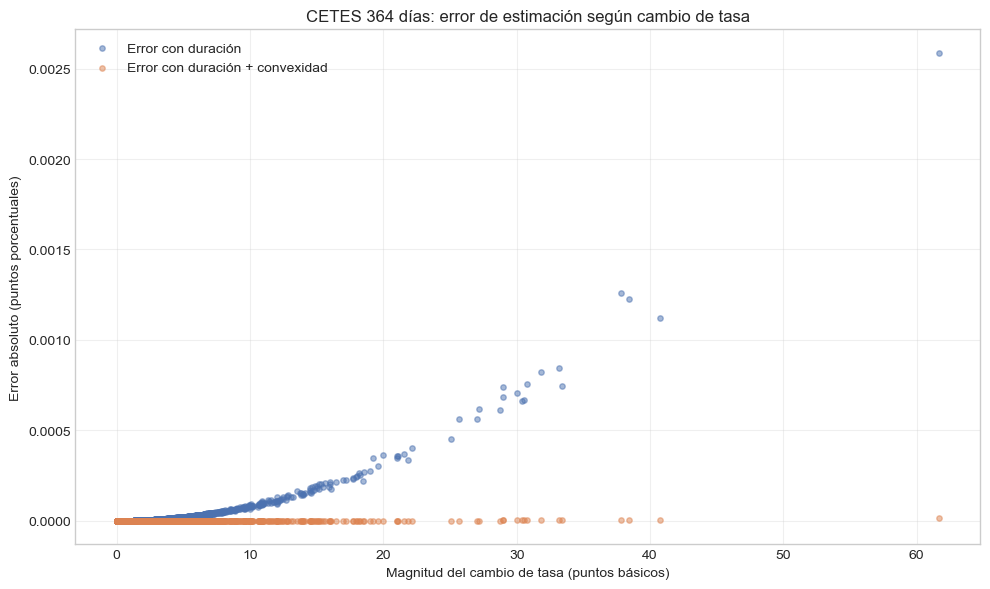

In [69]:
import matplotlib.pyplot as plt

# Trabajaremos con CETES de 364 días
grafica_364 = comparacion_historica[
    comparacion_historica["instrumento"] == 364
].copy()

# Magnitud del cambio en puntos básicos
grafica_364["cambio_pb_absoluto"] = (
    grafica_364["cambio_tasa"].abs() * 10000
)

# Ordenar los datos para visualizar la tendencia
grafica_364 = grafica_364.sort_values("cambio_pb_absoluto")

plt.figure(figsize=(10, 6))

plt.scatter(
    grafica_364["cambio_pb_absoluto"],
    grafica_364["error_duracion"],
    label="Error con duración",
    alpha=0.5,
    s=15
)

plt.scatter(
    grafica_364["cambio_pb_absoluto"],
    grafica_364["error_convexidad"],
    label="Error con duración + convexidad",
    alpha=0.5,
    s=15
)

plt.xlabel("Magnitud del cambio de tasa (puntos básicos)")
plt.ylabel("Error absoluto (puntos porcentuales)")
plt.title("CETES 364 días: error de estimación según cambio de tasa")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    carpeta / "Error_Duracion_Convexidad_364.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
from pathlib import Path
import pandas as pd

# Carpeta principal
carpeta = Path("Proyecto_Convexidad_CETES")
carpeta.mkdir(exist_ok=True)

# Crear subcarpetas
carpeta_graficas = carpeta / "Graficas"
carpeta_tablas = carpeta / "Tablas"
carpeta_presentacion = carpeta / "Presentacion"

for ruta in [
    carpeta_graficas,
    carpeta_tablas,
    carpeta_presentacion
]:
    ruta.mkdir(exist_ok=True)

# Tablas principales del proyecto
tablas = {
    "01_Validacion_Precios.xlsx": resumen_mercado,
    "02_Duracion_Convexidad.xlsx": resumen_sensibilidad,
    "03_Comparacion_Errores.xlsx": resumen_comparacion,
    "04_Base_Historica.xlsx": comparacion_historica
}

# Guardar archivos
for nombre, tabla in tablas.items():

    ruta = carpeta_tablas / nombre

    tabla.to_excel(
        ruta,
        index=False
    )

    print("Guardado:", ruta)

print("\nTodas las tablas se guardaron correctamente.")

Guardado: Proyecto_Convexidad_CETES\Tablas\01_Validacion_Precios.xlsx
Guardado: Proyecto_Convexidad_CETES\Tablas\02_Duracion_Convexidad.xlsx
Guardado: Proyecto_Convexidad_CETES\Tablas\03_Comparacion_Errores.xlsx
Guardado: Proyecto_Convexidad_CETES\Tablas\04_Base_Historica.xlsx

Todas las tablas se guardaron correctamente.


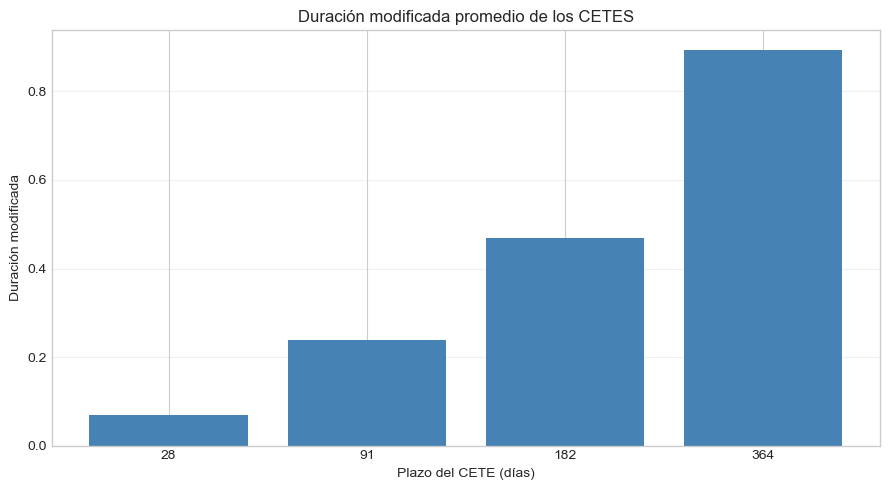

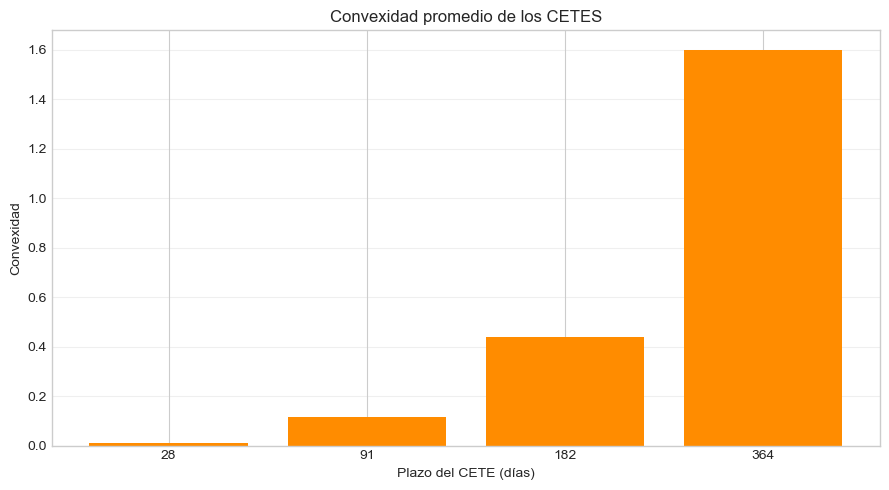

In [71]:
import matplotlib.pyplot as plt

# Preparar información
plazos = resumen_sensibilidad["instrumento"]

duracion = resumen_sensibilidad["duracion_promedio"]
convexidad = resumen_sensibilidad["convexidad_promedio"]

# Gráfica de duración
plt.figure(figsize=(9, 5))

plt.bar(
    plazos.astype(str),
    duracion,
    color="steelblue"
)

plt.title("Duración modificada promedio de los CETES")
plt.xlabel("Plazo del CETE (días)")
plt.ylabel("Duración modificada")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    carpeta_graficas / "01_Duracion_Promedio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Gráfica de convexidad
plt.figure(figsize=(9, 5))

plt.bar(
    plazos.astype(str),
    convexidad,
    color="darkorange"
)

plt.title("Convexidad promedio de los CETES")
plt.xlabel("Plazo del CETE (días)")
plt.ylabel("Convexidad")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    carpeta_graficas / "02_Convexidad_Promedio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

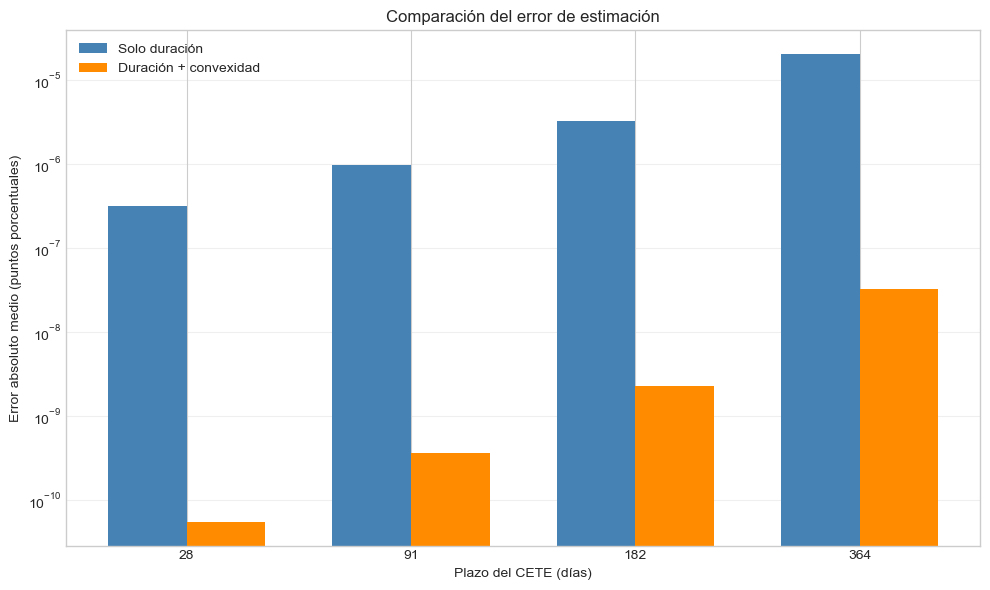

In [72]:
import matplotlib.pyplot as plt
import numpy as np

# Información de la comparación histórica
plazos = resumen_comparacion["instrumento"].astype(str)

error_duracion = resumen_comparacion["error_medio_duracion"]
error_convexidad = resumen_comparacion["error_medio_convexidad"]

# Posiciones de las barras
x = np.arange(len(plazos))
ancho = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - ancho/2,
    error_duracion,
    ancho,
    label="Solo duración",
    color="steelblue"
)

plt.bar(
    x + ancho/2,
    error_convexidad,
    ancho,
    label="Duración + convexidad",
    color="darkorange"
)

plt.yscale("log")

plt.xticks(x, plazos)

plt.xlabel("Plazo del CETE (días)")
plt.ylabel("Error absoluto medio (puntos porcentuales)")
plt.title("Comparación del error de estimación")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    carpeta_graficas / "03_Comparacion_Errores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

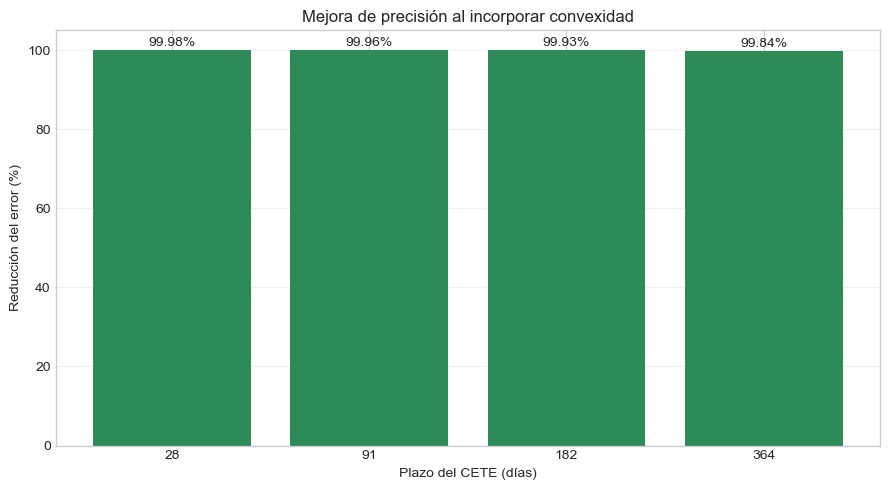

In [73]:
plt.figure(figsize=(9, 5))

plazos = resumen_comparacion["instrumento"].astype(str)
mejoras = resumen_comparacion["mejora_porcentual"]

barras = plt.bar(
    plazos,
    mejoras,
    color="seagreen"
)

plt.ylim(0, 105)

plt.xlabel("Plazo del CETE (días)")
plt.ylabel("Reducción del error (%)")
plt.title("Mejora de precisión al incorporar convexidad")

# Agregar porcentajes sobre las barras
for barra, mejora in zip(barras, mejoras):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{mejora:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    carpeta_graficas / "04_Reduccion_Error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
%pip install python-pptx

Note: you may need to restart the kernel to use updated packages.


In [76]:

from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN
from pathlib import Path

# --------------------------------------------------
# 1. CONFIGURACIÓN
# --------------------------------------------------

carpeta = Path("Proyecto_Convexidad_CETES")
carpeta_graficas = carpeta / "Graficas"
carpeta_presentacion = carpeta / "Presentacion"
carpeta_presentacion.mkdir(parents=True, exist_ok=True)

prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

AZUL = RGBColor(19, 43, 73)
VERDE = RGBColor(0, 135, 110)
GRIS = RGBColor(75, 85, 99)
BLANCO = RGBColor(255, 255, 255)

# --------------------------------------------------
# 2. FUNCIONES PARA CREAR DIAPOSITIVAS
# --------------------------------------------------

def texto(slide, contenido, x, y, ancho, alto,
          tamano=20, color=GRIS, negrita=False):

    caja = slide.shapes.add_textbox(
        Inches(x), Inches(y),
        Inches(ancho), Inches(alto)
    )

    marco = caja.text_frame
    marco.word_wrap = True

    for i, linea in enumerate(contenido.split("\n")):
        p = marco.paragraphs[0] if i == 0 else marco.add_paragraph()
        p.text = linea
        p.font.size = Pt(tamano)
        p.font.bold = negrita
        p.font.color.rgb = color
        p.space_after = Pt(14)

    return caja


def nueva_diapositiva(titulo):
    slide = prs.slides.add_slide(prs.slide_layouts[6])

    texto(slide, titulo, 0.7, 0.35, 12, 0.65,
          tamano=28, color=AZUL, negrita=True)

    # Línea decorativa
    from pptx.enum.shapes import MSO_SHAPE

    linea = slide.shapes.add_shape(
        MSO_SHAPE.RECTANGLE,
        Inches(0.7), Inches(1.12),
        Inches(11.9), Inches(0.045)
    )
    linea.fill.solid()
    linea.fill.fore_color.rgb = VERDE
    linea.line.fill.background()

    return slide


def agregar_grafica(slide, nombre):
    ruta = carpeta_graficas / nombre

    if ruta.exists():
        slide.shapes.add_picture(
            str(ruta),
            Inches(2.0), Inches(1.4),
            width=Inches(9.3)
        )
    else:
        texto(slide, f"No se encontró: {nombre}",
              1, 2, 11, 1, tamano=18)


def agregar_tabla(slide, df, columnas, x=0.8, y=1.7,
                  ancho=11.7, alto=3.5):

    datos = df[columnas].copy()
    filas = len(datos) + 1

    tabla = slide.shapes.add_table(
        filas, len(columnas),
        Inches(x), Inches(y),
        Inches(ancho), Inches(alto)
    ).table

    for j, columna in enumerate(columnas):
        celda = tabla.cell(0, j)
        celda.text = columna.replace("_", " ").title()
        celda.fill.solid()
        celda.fill.fore_color.rgb = AZUL

    for i, fila in enumerate(datos.itertuples(index=False), start=1):
        for j, valor in enumerate(fila):
            if isinstance(valor, (float, int)):
                celda_texto = f"{valor:.6g}"
            else:
                celda_texto = str(valor)

            tabla.cell(i, j).text = celda_texto

    for i in range(filas):
        for j in range(len(columnas)):
            celda = tabla.cell(i, j)

            for parrafo in celda.text_frame.paragraphs:
                parrafo.alignment = PP_ALIGN.CENTER
                for run in parrafo.runs:
                    run.font.size = Pt(12)
                    run.font.color.rgb = (
                        BLANCO if i == 0 else AZUL
                    )

# --------------------------------------------------
# 3. DIAPOSITIVAS
# --------------------------------------------------

# 1. Portada
slide = prs.slides.add_slide(prs.slide_layouts[6])

texto(slide, "ANÁLISIS DE DURACIÓN Y CONVEXIDAD",
      1, 1.7, 11.5, 1,
      tamano=34, color=AZUL, negrita=True)

texto(slide, "Aplicación a los CETES del mercado mexicano",
      1, 2.8, 11, 0.7,
      tamano=23, color=VERDE)

texto(slide, "Periodo de análisis: noviembre 2016 - noviembre 2026\n"
      "Fuente: Banco de México | Análisis realizado en Python",
      1, 4.5, 11, 1.2, tamano=17)

# 2. Introducción
slide = nueva_diapositiva("Introducción y planteamiento del problema")

texto(slide,
      "Los precios de los instrumentos de deuda cambian cuando "
      "se modifican las tasas de interés.\n"
      "La duración modificada permite aproximar esta sensibilidad, "
      "pero utiliza una relación lineal.\n"
      "La convexidad incorpora la curvatura de la relación "
      "precio-rendimiento y puede mejorar la precisión.",
      1, 1.8, 11.3, 4, tamano=22)

# 3. Objetivos
slide = nueva_diapositiva("Objetivos de la investigación")

texto(slide,
      "Objetivo general:\n"
      "Evaluar la utilidad de la duración modificada y la convexidad "
      "para estimar cambios en los precios de los CETES.\n\n"
      "Objetivos específicos:\n"
      "• Analizar cuatro plazos: 28, 91, 182 y 364 días.\n"
      "• Validar la fórmula de valoración con datos de BANXICO.\n"
      "• Comparar los errores de ambas aproximaciones.",
      1, 1.5, 11.4, 5.5, tamano=19)

# 4. Fundamentos CETES
slide = nueva_diapositiva("Fundamentos teóricos de los CETES")

texto(slide,
      "Los CETES son instrumentos de deuda pública a descuento "
      "que no pagan cupones.\n\n"
      "Precio teórico:\n"
      "P = VN / [1 + r(d/360)]\n\n"
      "VN = Valor nominal ($10)\n"
      "r = Tasa de rendimiento anual en decimal\n"
      "d = Días restantes hasta el vencimiento",
      1, 1.5, 11.5, 5, tamano=21)

# 5. Duración y convexidad
slide = nueva_diapositiva("Duración modificada y convexidad")

texto(slide,
      "Sea t = d/360 y r la tasa anual en decimal.\n\n"
      "Duración modificada:\n"
      "D = t / (1 + r·t)\n\n"
      "Convexidad:\n"
      "C = 2t² / (1 + r·t)²\n\n"
      "Aproximación del cambio de precio:\n"
      "ΔP/P ≈ -D·Δr + 0.5·C·(Δr)²",
      1, 1.4, 11.5, 5.8, tamano=20)

# 6. Metodología
slide = nueva_diapositiva("Metodología y fuente de información")

texto(slide,
      "Fuente: Banco de México, cuadro CF300.\n\n"
      "• Periodo: noviembre 2016 a noviembre 2026.\n"
      "• 10,064 observaciones de instrumento-fecha.\n"
      "• Plazos analizados: 28, 91, 182 y 364 días.\n"
      "• Variables: plazo restante, precio limpio y rendimiento.\n"
      "• Herramientas: Python, pandas y matplotlib.\n\n"
      "Se mantiene constante el plazo inicial al evaluar "
      "los movimientos de tasas observados.",
      1, 1.4, 11.5, 5.7, tamano=19)

# 7. Validación
slide = nueva_diapositiva("Validación del modelo de valoración")

agregar_tabla(
    slide,
    resumen_mercado,
    ["instrumento", "observaciones",
     "error_promedio", "error_maximo"]
)

texto(slide,
      "Los precios teóricos prácticamente coinciden con los "
      "publicados por BANXICO. Esta prueba verifica la consistencia "
      "de la fórmula, no su capacidad predictiva.",
      1, 5.6, 11.3, 1.2, tamano=17)

# 8. Duración
slide = nueva_diapositiva("Sensibilidad por plazo: duración")
agregar_grafica(slide, "01_Duracion_Promedio.png")

# 9. Convexidad
slide = nueva_diapositiva("Sensibilidad por plazo: convexidad")
agregar_grafica(slide, "02_Convexidad_Promedio.png")

# 10. Errores
slide = nueva_diapositiva("Comparación de errores de estimación")
agregar_grafica(slide, "03_Comparacion_Errores.png")

# 11. Resultados
slide = nueva_diapositiva("Reducción del error al incorporar convexidad")
agregar_grafica(slide, "04_Reduccion_Error.png")

# 12. Conclusiones
slide = nueva_diapositiva("Conclusiones y limitaciones")

texto(slide,
      "• Los CETES de mayor plazo presentan mayor duración y convexidad.\n"
      "• La duración aproxima adecuadamente cambios pequeños de tasas.\n"
      "• Incorporar convexidad redujo el error medio más de 99% "
      "en los cuatro plazos.\n"
      "• La mejora representa precisión matemática, no rentabilidad.\n\n"
      "Limitación: los cambios de precio se calcularon manteniendo "
      "constante el plazo, utilizando tasas observadas de series "
      "'on the run'. No representan rendimientos realizados ni "
      "una validación predictiva independiente.",
      1, 1.4, 11.4, 5.8, tamano=19)

# --------------------------------------------------
# 4. GUARDAR PRESENTACIÓN
# --------------------------------------------------

archivo = carpeta_presentacion / "Proyecto_Convexidad_CETES.pptx"

prs.save(str(archivo))

print("Presentación generada correctamente.")
print("Archivo:", archivo.resolve())
print("Número de diapositivas:", len(prs.slides))


Presentación generada correctamente.
Archivo: C:\Users\Ernesto Segura\Proyecto_Convexidad_CETES\Presentacion\Proyecto_Convexidad_CETES.pptx
Número de diapositivas: 12
